# DX799 Capstone — Week 9: Gradient Boosting

This analysis tests whether additional tree-based flexibility improves prediction of two continuous cardiovascular measurements: maximum heart rate in Statlog and systolic blood pressure in Framingham. Learning rate, number of estimators, tree depth, and regularization are examined separately before model tuning. A supplementary classification comparison connects the results to the disease outcomes studied in Week 8.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              GradientBoostingClassifier)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
CV_CLASS = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 1. Sequential residual correction

In squared-error regression, gradient boosting starts with the mean target value. Each subsequent tree estimates remaining residuals (observed minus predicted), and its contribution is reduced by the learning rate. Unlike a random forest, the trees are fitted sequentially rather than independently.

In [2]:
# A two-stage residual fit using the three observations in the course example.
y_demo = np.array([1.8, 1.3, 2.6])
group = np.array([0, 0, 1]).reshape(-1, 1)
pred = np.repeat(y_demo.mean(), len(y_demo))
rows = [{"Stage": "Initial mean", "RMSE": np.sqrt(np.mean((y_demo - pred)**2))}]

for stage in range(1, 3):
    residuals = y_demo - pred
    stump = DecisionTreeRegressor(max_depth=1, random_state=SEED)
    stump.fit(group, residuals)
    correction = 0.5 * stump.predict(group)
    pred = pred + correction
    rows.append({"Stage": f"Stump {stage}",
                 "RMSE": np.sqrt(np.mean((y_demo - pred)**2))})

example = pd.DataFrame({"Actual": y_demo, "Final prediction": pred,
                        "Remaining residual": y_demo - pred})
display(pd.DataFrame(rows).round(3), example.round(3))

,Stage,RMSE
0,Initial mean,0.535
1,Stump 1,0.321
2,Stump 2,0.239


,Actual,Final prediction,Remaining residual
0,1.8,1.638,0.162
1,1.3,1.638,-0.338
2,2.6,2.425,0.175


## 2. Data and regression targets

The same preprocessed Statlog Heart Disease and Framingham datasets from earlier capstone work are used. Statlog predicts `thalach` from `age`, `chol`, and `trestbps`; Framingham predicts `sysBP` from `age`, `BMI`, and `totChol`. These are distinct regression tasks, not direct predictions of heart-disease status. Each uses an 80/20 split and five-fold training cross-validation.

In [3]:
BASE = "https://raw.githubusercontent.com/piraterashik/DX799-Data-Science-Capstone/main/"
heart = pd.read_csv(BASE + "preprocessed_heart_disease.csv")
framingham = pd.read_csv(BASE + "preprocessed_framingham.csv")

REGRESSION = {
    "Statlog": {"data": heart, "target": "thalach",
                "features": ["age", "chol", "trestbps"], "unit": "bpm"},
    "Framingham": {"data": framingham, "target": "sysBP",
                  "features": ["age", "BMI", "totChol"], "unit": "mmHg"}
}
SPLITS = {}
for name, cfg in REGRESSION.items():
    cols = cfg["features"] + [cfg["target"]]
    data = cfg["data"][cols].apply(pd.to_numeric, errors="coerce")
    data = data.loc[data[cfg["target"]].notna()]
    X = data[cfg["features"]]
    y = data[cfg["target"]]
    SPLITS[name] = train_test_split(X, y, test_size=0.20, random_state=SEED)

print("Regressions: Statlog — maximum heart rate; Framingham — systolic blood pressure")
print({name: (len(parts[0]), len(parts[1])) for name, parts in SPLITS.items()})

Regressions: Statlog — maximum heart rate; Framingham — systolic blood pressure
{'Statlog': (216, 54), 'Framingham': (3390, 848)}


## 3. Exploratory analysis

Target distributions, predictor correlations, and missing values are examined on the training portion. Outlying measurements and nonlinear patterns may influence regression error, particularly RMSE, which places extra weight on large mistakes.

,Dataset,Training rows,Target,Mean,SD,Skew,Min,Max,Missing predictors,Strongest correlation,Correlation
0,Statlog,216,thalach,149.079,22.877,-0.591,71.0,202.0,0,age,-0.405
1,Framingham,3390,sysBP,132.390,22.120,1.144,83.5,295.0,0,age,0.395


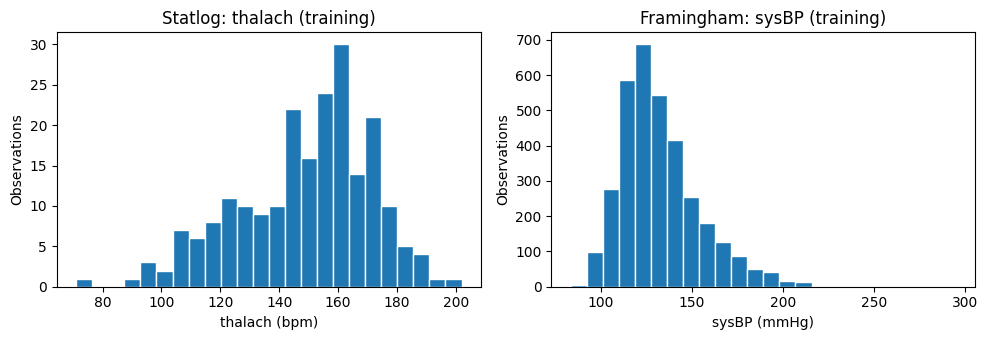

In [4]:
eda_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, cfg) in zip(axes, REGRESSION.items()):
    Xtr, Xte, ytr, yte = SPLITS[name]
    corr = Xtr.corrwith(ytr).dropna().sort_values(key=lambda s: s.abs(), ascending=False)
    eda_rows.append({"Dataset": name, "Training rows": len(Xtr),
                     "Target": cfg["target"], "Mean": ytr.mean(),
                     "SD": ytr.std(), "Skew": ytr.skew(),
                     "Min": ytr.min(), "Max": ytr.max(),
                     "Missing predictors": int(Xtr.isna().sum().sum()),
                     "Strongest correlation": corr.index[0],
                     "Correlation": corr.iloc[0]})
    ax.hist(ytr, bins=24, edgecolor="white")
    ax.set(title=f"{name}: {cfg['target']} (training)",
           xlabel=f"{cfg['target']} ({cfg['unit']})", ylabel="Observations")
eda = pd.DataFrame(eda_rows)
display(eda.round(3))
plt.tight_layout(); plt.show()

## 4. Baseline model comparison

Mean prediction, linear regression, random forest, and default gradient boosting provide initial reference points. RMSE measures error in the original outcome units, while R² measures improvement relative to a mean-only prediction. The training–validation RMSE gap provides an indication of overfitting.

In [5]:
def regression_pipeline(estimator):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("model", estimator)])

REG_SCORING = {"RMSE": "neg_root_mean_squared_error", "R2": "r2"}

def cv_row(name, estimator, setting, experiment):
    Xtr, _, ytr, _ = SPLITS[name]
    scores = cross_validate(regression_pipeline(estimator), Xtr, ytr,
                            cv=CV, scoring=REG_SCORING, return_train_score=True)
    train_rmse = -scores["train_RMSE"].mean()
    cv_rmse = -scores["test_RMSE"].mean()
    return {"Dataset": name, "Experiment": experiment, "Setting": setting,
            "Train RMSE": train_rmse, "CV RMSE": cv_rmse,
            "CV RMSE SD": scores["test_RMSE"].std(),
            "CV R2": scores["test_R2"].mean(),
            "RMSE gap": cv_rmse - train_rmse}

BASELINES = {
    "Mean only": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=150, max_depth=5,
                                          min_samples_leaf=3, random_state=SEED,
                                          n_jobs=-1),
    "Gradient boosting (default)": GradientBoostingRegressor(random_state=SEED)
}
baseline_results = pd.DataFrame([
    cv_row(name, clone(est), label, "Baseline")
    for name in REGRESSION for label, est in BASELINES.items()
])
display(baseline_results.round(3))

,Dataset,Experiment,Setting,Train RMSE,CV RMSE,CV RMSE SD,CV R2,RMSE gap
0,Statlog,Baseline,Mean only,22.811,22.863,1.528,-0.019,0.052
1,Statlog,Baseline,Linear regression,20.748,21.189,1.553,0.123,0.442
2,Statlog,Baseline,Random forest,16.131,22.256,1.975,0.035,6.125
3,Statlog,Baseline,Gradient boosting (default),11.445,23.674,2.400,-0.097,12.229
4,Framingham,Baseline,Mean only,22.113,22.116,0.895,-0.005,0.003
5,Framingham,Baseline,Linear regression,19.198,19.227,0.674,0.240,0.028
6,Framingham,Baseline,Random forest,18.335,19.415,0.681,0.225,1.080
7,Framingham,Baseline,Gradient boosting (default),17.835,19.615,0.690,0.209,1.780


## 5. Learning rate and number of trees

The learning rate sets how much each new tree changes the prediction; `n_estimators` sets the number of sequential trees. Smaller learning rates often need more trees. The comparison uses depth-2 trees and five-fold cross-validation.

,Dataset,Experiment,Setting,Train RMSE,CV RMSE,CV RMSE SD,CV R2,RMSE gap,Learning rate,Trees
12,Framingham,Learning rate,"LR=0.1, trees=50",18.748,19.411,0.677,0.226,0.662,0.10,50
10,Framingham,Learning rate,"LR=0.03, trees=150",18.792,19.413,0.678,0.226,0.621,0.03,150
11,Framingham,Learning rate,"LR=0.03, trees=350",18.507,19.443,0.662,0.223,0.937,0.03,350
13,Framingham,Learning rate,"LR=0.1, trees=150",18.327,19.509,0.699,0.218,1.182,0.10,150
15,Framingham,Learning rate,"LR=0.3, trees=50",18.360,19.534,0.682,0.216,1.174,0.30,50
14,Framingham,Learning rate,"LR=0.1, trees=350",17.731,19.680,0.668,0.204,1.949,0.10,350
0,Statlog,Learning rate,"LR=0.03, trees=50",19.832,21.905,2.055,0.066,2.073,0.03,50
1,Statlog,Learning rate,"LR=0.03, trees=150",18.301,22.131,2.341,0.046,3.830,0.03,150
3,Statlog,Learning rate,"LR=0.1, trees=50",18.020,22.158,2.372,0.044,4.138,0.10,50
2,Statlog,Learning rate,"LR=0.03, trees=350",16.299,22.813,2.560,-0.015,6.514,0.03,350


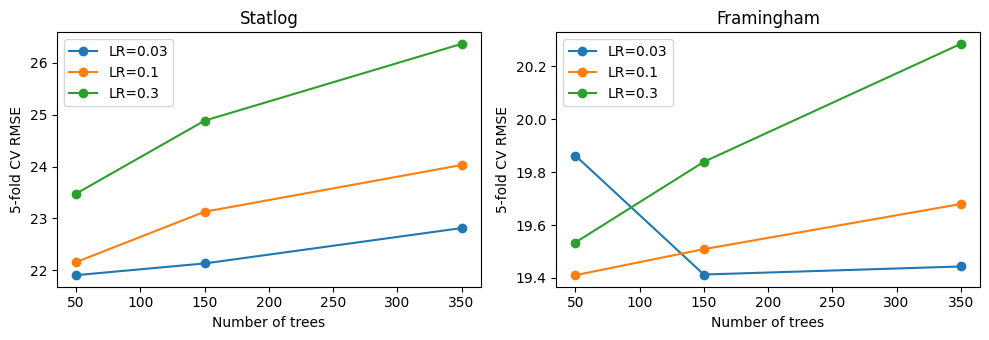

In [6]:
learning_rows = []
for name in REGRESSION:
    for rate in [0.03, 0.10, 0.30]:
        for trees in [50, 150, 350]:
            model = GradientBoostingRegressor(
                learning_rate=rate, n_estimators=trees, max_depth=2,
                min_samples_leaf=5, random_state=SEED)
            row = cv_row(name, model, f"LR={rate}, trees={trees}", "Learning rate")
            row.update({"Learning rate": rate, "Trees": trees})
            learning_rows.append(row)
learning_results = pd.DataFrame(learning_rows)
display(learning_results.sort_values(["Dataset", "CV RMSE"]).groupby("Dataset").head(6).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, REGRESSION):
    subset = learning_results[learning_results.Dataset == name]
    for rate, group in subset.groupby("Learning rate"):
        group = group.sort_values("Trees")
        ax.plot(group["Trees"], group["CV RMSE"], marker="o", label=f"LR={rate}")
    ax.set(title=name, xlabel="Number of trees", ylabel="5-fold CV RMSE")
    ax.legend()
plt.tight_layout(); plt.show()

## 6. Tree depth and overfitting

Tree depth controls the complexity of individual learners. Training and validation RMSE are compared across depths and ensemble sizes to identify where additional flexibility stops improving generalization.

,Dataset,Experiment,Setting,Train RMSE,CV RMSE,CV RMSE SD,CV R2,RMSE gap,Max depth,Trees
9,Framingham,Tree depth,"depth=1, trees=50",19.208,19.498,0.710,0.219,0.291,1,50
10,Framingham,Tree depth,"depth=1, trees=150",18.905,19.351,0.680,0.230,0.446,1,150
11,Framingham,Tree depth,"depth=1, trees=350",18.815,19.349,0.688,0.231,0.534,1,350
12,Framingham,Tree depth,"depth=2, trees=50",18.748,19.411,0.677,0.226,0.662,2,50
13,Framingham,Tree depth,"depth=2, trees=150",18.327,19.509,0.699,0.218,1.182,2,150
14,Framingham,Tree depth,"depth=2, trees=350",17.731,19.680,0.668,0.204,1.949,2,350
15,Framingham,Tree depth,"depth=4, trees=50",17.732,19.557,0.667,0.214,1.824,4,50
16,Framingham,Tree depth,"depth=4, trees=150",16.455,19.904,0.752,0.186,3.448,4,150
17,Framingham,Tree depth,"depth=4, trees=350",14.510,20.468,0.743,0.139,5.957,4,350
0,Statlog,Tree depth,"depth=1, trees=50",19.958,21.771,1.802,0.077,1.813,1,50


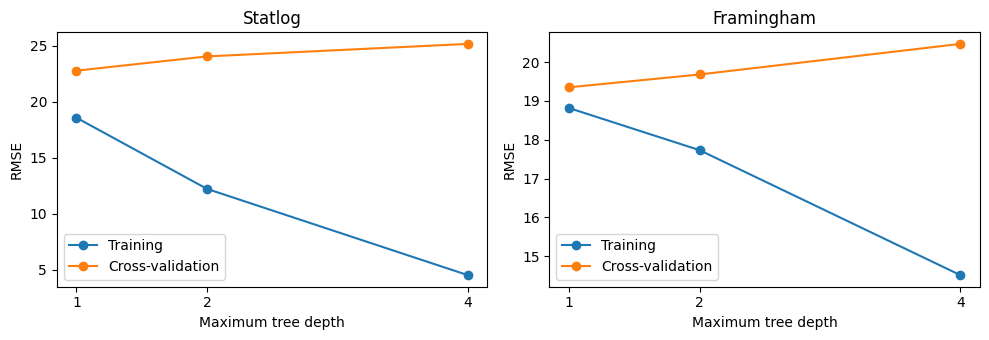

In [7]:
depth_rows = []
for name in REGRESSION:
    for depth in [1, 2, 4]:
        for trees in [50, 150, 350]:
            model = GradientBoostingRegressor(
                learning_rate=0.10, n_estimators=trees, max_depth=depth,
                min_samples_leaf=5, random_state=SEED)
            row = cv_row(name, model, f"depth={depth}, trees={trees}", "Tree depth")
            row.update({"Max depth": depth, "Trees": trees})
            depth_rows.append(row)
depth_results = pd.DataFrame(depth_rows)
display(depth_results.sort_values(["Dataset", "Max depth", "Trees"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, REGRESSION):
    subset = depth_results[(depth_results.Dataset == name) & (depth_results.Trees == 350)]
    ax.plot(subset["Max depth"], subset["Train RMSE"], marker="o", label="Training")
    ax.plot(subset["Max depth"], subset["CV RMSE"], marker="o", label="Cross-validation")
    ax.set(title=name, xlabel="Maximum tree depth", ylabel="RMSE", xticks=[1, 2, 4])
    ax.legend()
plt.tight_layout(); plt.show()

## 7. Regularization

Minimum split size and leaf size restrict highly specific rules; subsampling trains each tree on part of the data. Each intervention is compared with the same unregularized reference configuration, then combined to assess generalization.

In [8]:
REG_SETTINGS = {
    "Reference": {"max_depth": 3, "min_samples_split": 2,
                  "min_samples_leaf": 1, "subsample": 1.0},
    "Shallower trees": {"max_depth": 1, "min_samples_split": 2,
                        "min_samples_leaf": 1, "subsample": 1.0},
    "Larger leaves": {"max_depth": 3, "min_samples_split": 2,
                      "min_samples_leaf": 10, "subsample": 1.0},
    "Larger minimum split": {"max_depth": 3, "min_samples_split": 20,
                             "min_samples_leaf": 1, "subsample": 1.0},
    "Subsample 70%": {"max_depth": 3, "min_samples_split": 2,
                      "min_samples_leaf": 1, "subsample": 0.7},
    "Combined controls": {"max_depth": 2, "min_samples_split": 20,
                          "min_samples_leaf": 10, "subsample": 0.7}
}
reg_rows = []
for name in REGRESSION:
    for label, params in REG_SETTINGS.items():
        model = GradientBoostingRegressor(
            learning_rate=0.10, n_estimators=200, random_state=SEED, **params)
        reg_rows.append(cv_row(name, model, label, "Regularization"))
regularization_results = pd.DataFrame(reg_rows)
display(regularization_results.round(3))

,Dataset,Experiment,Setting,Train RMSE,CV RMSE,CV RMSE SD,CV R2,RMSE gap
0,Statlog,Regularization,Reference,7.085,25.125,2.312,-0.238,18.040
1,Statlog,Regularization,Shallower trees,18.717,22.473,2.115,0.017,3.756
2,Statlog,Regularization,Larger leaves,12.529,24.055,1.977,-0.130,11.526
3,Statlog,Regularization,Larger minimum split,10.047,24.868,2.463,-0.213,14.821
4,Statlog,Regularization,Subsample 70%,6.573,25.075,2.040,-0.241,18.502
5,Statlog,Regularization,Combined controls,14.882,23.104,2.292,-0.042,8.222
6,Framingham,Regularization,Reference,17.020,19.867,0.710,0.189,2.847
7,Framingham,Regularization,Shallower trees,18.873,19.351,0.683,0.230,0.478
8,Framingham,Regularization,Larger leaves,17.447,19.759,0.710,0.198,2.311
9,Framingham,Regularization,Larger minimum split,17.268,19.811,0.726,0.193,2.543


## 8. Hyperparameter selection

A complete five-fold grid search evaluates 16 configurations per dataset (two values each for learning rate, tree count, depth, and leaf size; subsampling is held at 0.8). The lowest cross-validation RMSE determines the selected model. The test set remains unused during selection.

In [9]:
PARAM_GRID = {
    "model__learning_rate": [0.05, 0.10],
    "model__n_estimators": [75, 200],
    "model__max_depth": [1, 3],
    "model__min_samples_leaf": [1, 10],
    "model__subsample": [0.8]
}
SEARCHES = {}
tuning_rows = []
for name in REGRESSION:
    Xtr, _, ytr, _ = SPLITS[name]
    search = GridSearchCV(
        regression_pipeline(GradientBoostingRegressor(
            min_samples_split=10, random_state=SEED)),
        param_grid=PARAM_GRID, scoring="neg_root_mean_squared_error",
        cv=CV, refit=True, n_jobs=1, return_train_score=True)
    search.fit(Xtr, ytr)
    SEARCHES[name] = search
    best_idx = search.best_index_
    tuning_rows.append({"Dataset": name, "CV RMSE": -search.best_score_,
                        "Train RMSE (CV folds)": -search.cv_results_["mean_train_score"][best_idx],
                        "Configurations": len(search.cv_results_["params"]),
                        **{key.replace("model__", ""): value
                           for key, value in search.best_params_.items()}})
tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results.round(3))

,Dataset,CV RMSE,Train RMSE (CV folds),Configurations,learning_rate,max_depth,min_samples_leaf,n_estimators,subsample
0,Statlog,21.760,19.887,16,0.05,1,1,75,0.8
1,Framingham,19.321,18.939,16,0.05,1,1,200,0.8


## 9. Held-out regression evaluation

Only after tuning are predictions evaluated against the untouched test sets. Mean-only, linear regression, random forest, default gradient boosting, and tuned gradient boosting are compared with RMSE, MAE, and R².

,Dataset,Model,Test RMSE,Test MAE,Test R2
0,Statlog,Mean only,24.318,20.139,-0.015
1,Statlog,Linear regression,22.211,18.924,0.153
2,Statlog,Random forest,22.248,18.507,0.150
3,Statlog,Gradient boosting (default),23.590,19.479,0.045
4,Statlog,Gradient boosting (tuned),22.558,19.189,0.126
5,Framingham,Mean only,21.709,16.497,-0.000
6,Framingham,Linear regression,19.363,14.365,0.204
7,Framingham,Random forest,19.498,14.402,0.193
8,Framingham,Gradient boosting (default),19.600,14.502,0.185
9,Framingham,Gradient boosting (tuned),19.499,14.423,0.193


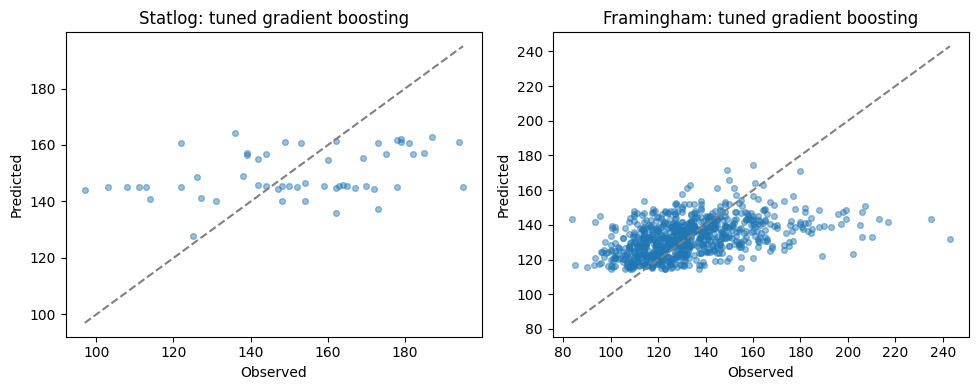

In [10]:
heldout_rows = []
predictions = {}
for name, cfg in REGRESSION.items():
    Xtr, Xte, ytr, yte = SPLITS[name]
    candidates = {label: regression_pipeline(clone(est))
                  for label, est in BASELINES.items()}
    candidates["Gradient boosting (tuned)"] = SEARCHES[name].best_estimator_
    for label, model in candidates.items():
        if label != "Gradient boosting (tuned)":
            model.fit(Xtr, ytr)
        estimated = model.predict(Xte)
        heldout_rows.append({"Dataset": name, "Model": label,
                             "Test RMSE": np.sqrt(mean_squared_error(yte, estimated)),
                             "Test MAE": mean_absolute_error(yte, estimated),
                             "Test R2": r2_score(yte, estimated)})
        if label == "Gradient boosting (tuned)":
            predictions[name] = (yte.to_numpy(), estimated)
heldout_results = pd.DataFrame(heldout_rows)
display(heldout_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, (actual, estimated)) in zip(axes, predictions.items()):
    ax.scatter(actual, estimated, alpha=0.45, s=17)
    low = min(actual.min(), estimated.min())
    high = max(actual.max(), estimated.max())
    ax.plot([low, high], [low, high], linestyle="--", color="gray")
    ax.set(title=f"{name}: tuned gradient boosting",
           xlabel="Observed", ylabel="Predicted")
plt.tight_layout(); plt.show()

## 10. Disease classification extension

The regressions above estimate clinical measurements; they do not classify heart disease. A separate gradient-boosting classification experiment uses the original `target` and `TenYearCHD` outcomes to connect this week's work with Week 8. Classifier selection uses average precision (AP), which is informative for the imbalanced Framingham outcome.

In [11]:
CLASSIFICATION = {
    "Statlog": {"data": heart, "target": "target",
                "numeric": ["age", "trestbps", "chol", "thalach", "oldpeak"],
                "binary": ["sex", "fbs", "exang"],
                "categorical": ["cp", "restecg", "slope", "ca", "thal"]},
    "Framingham": {"data": framingham, "target": "TenYearCHD",
                   "numeric": ["age", "cigsPerDay", "totChol", "sysBP", "diaBP",
                               "BMI", "heartRate", "glucose"],
                   "binary": ["male", "currentSmoker", "BPMeds", "prevalentStroke",
                              "prevalentHyp", "diabetes"],
                   "categorical": ["education"]}
}

CLASS_SPLITS, CLASS_SEARCHES, CLASS_THRESHOLDS = {}, {}, {}
classification_tuning_rows = []
for name, cfg in CLASSIFICATION.items():
    cols = cfg["numeric"] + cfg["binary"] + cfg["categorical"]
    X = cfg["data"][cols].copy()
    y = cfg["data"][cfg["target"]].astype(int)
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.20, random_state=SEED, stratify=y)
    CLASS_SPLITS[name] = (Xtr, Xte, ytr, yte)

    numeric_cols = cfg["numeric"] + cfg["binary"]
    categorical_cols = cfg["categorical"]
    prep = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ])
    pipe = Pipeline([
        ("preprocess", prep),
        ("model", GradientBoostingClassifier(
            min_samples_leaf=5, subsample=0.8, random_state=SEED))
    ])
    search = GridSearchCV(pipe, {
        "model__learning_rate": [0.05, 0.10],
        "model__n_estimators": [75, 200],
        "model__max_depth": [1, 2]
    }, scoring="average_precision", cv=CV_CLASS, n_jobs=1, refit=True)
    search.fit(Xtr, ytr)
    CLASS_SEARCHES[name] = search

    oof = cross_val_predict(clone(search.best_estimator_), Xtr, ytr,
                           cv=CV_CLASS, method="predict_proba")[:, 1]
    precision, recall, thresholds = precision_recall_curve(ytr, oof)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(
        precision[:-1] + recall[:-1], 1e-12)
    selected = float(thresholds[np.argmax(f1)])
    CLASS_THRESHOLDS[name] = selected
    classification_tuning_rows.append({
        "Dataset": name, "Best CV AP": search.best_score_,
        "OOF AP": average_precision_score(ytr, oof),
        "Threshold (CV F1)": selected,
        **{key.replace("model__", ""): value for key, value in search.best_params_.items()}
    })
classification_tuning = pd.DataFrame(classification_tuning_rows)
display(classification_tuning.round(3))

,Dataset,Best CV AP,OOF AP,Threshold (CV F1),learning_rate,max_depth,n_estimators
0,Statlog,0.907,0.902,0.662,0.05,1,200
1,Framingham,0.352,0.345,0.170,0.05,2,200


,Dataset,Threshold setting,Threshold,Test AP,Test AUC,Test precision,Test recall,Test F1,TP,FP,TN,FN
0,Statlog,Default 0.50,0.500,0.881,0.915,0.808,0.875,0.840,21,5,25,3
1,Statlog,CV F1 threshold,0.662,0.881,0.915,0.826,0.792,0.809,19,4,26,5
2,Framingham,Default 0.50,0.500,0.263,0.678,0.308,0.062,0.103,8,18,701,121
3,Framingham,CV F1 threshold,0.170,0.263,0.678,0.247,0.473,0.324,61,186,533,68


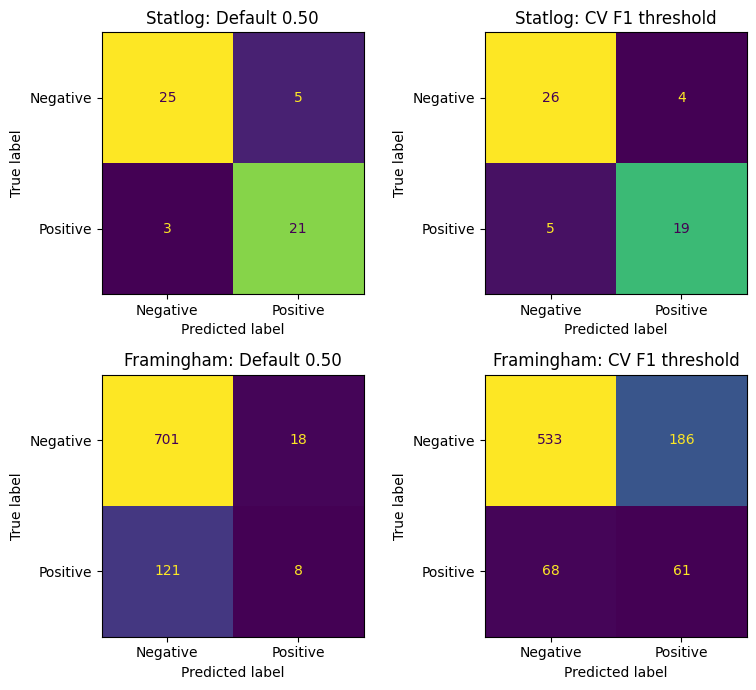

In [12]:
classification_rows = []
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for row, name in enumerate(CLASSIFICATION):
    _, Xte, _, yte = CLASS_SPLITS[name]
    prob = CLASS_SEARCHES[name].best_estimator_.predict_proba(Xte)[:, 1]
    for col, (label, threshold) in enumerate([
        ("Default 0.50", 0.50), ("CV F1 threshold", CLASS_THRESHOLDS[name])
    ]):
        pred = (prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
        classification_rows.append({"Dataset": name, "Threshold setting": label,
                                    "Threshold": threshold,
                                    "Test AP": average_precision_score(yte, prob),
                                    "Test AUC": roc_auc_score(yte, prob),
                                    "Test precision": precision_score(yte, pred, zero_division=0),
                                    "Test recall": recall_score(yte, pred, zero_division=0),
                                    "Test F1": f1_score(yte, pred, zero_division=0),
                                    "TP": tp, "FP": fp, "TN": tn, "FN": fn})
        ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=[0, 1]),
                               display_labels=["Negative", "Positive"]).plot(
            ax=axes[row, col], colorbar=False)
        axes[row, col].set_title(f"{name}: {label}")
classification_results = pd.DataFrame(classification_rows)
display(classification_results.round(3))
plt.tight_layout(); plt.show()

## 10A. Classification Comparison at Equal Referral Capacity

The Week 8 KNN settings and Week 9 gradient boosting classifiers are compared on identical held-out patients. Both models are evaluated at their original cross-validated thresholds and at fixed referral counts.

The fixed-capacity analysis examines how many future CHD cases each model identifies when the same number of patients is selected for follow-up. A paired bootstrap is used to estimate uncertainty in the performance differences. The comparison remains retrospective and does not establish a clinically validated referral policy.

In [15]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

PRED = {}

for name, cfg in CLASSIFICATION.items():
    Xtr, Xte, ytr, yte = CLASS_SPLITS[name]

    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])
    binary = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent"))
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        ))
    ])

    prep = ColumnTransformer([
        ("numeric", numeric, cfg["numeric"]),
        ("binary", binary, cfg["binary"]),
        ("categorical", categorical, cfg["categorical"])
    ], sparse_threshold=0)

    metric = "manhattan" if name == "Statlog" else "euclidean"

    knn = Pipeline([
        ("prep", prep),
        ("knn", KNeighborsClassifier(
            n_neighbors=31,
            weights="distance",
            metric=metric,
            algorithm="brute"
        ))
    ])

    knn.fit(Xtr, ytr)

    PRED[name] = {
        "y": yte.to_numpy().astype(int),
        "KNN": knn.predict_proba(Xte)[:, 1],
        "Boosting": CLASS_SEARCHES[name].best_estimator_.predict_proba(Xte)[:, 1]
    }

    for model in ["KNN", "Boosting"]:
        print(
            name, model,
            "AP:", round(average_precision_score(
                PRED[name]["y"], PRED[name][model]
            ), 3),
            "AUC:", round(roc_auc_score(
                PRED[name]["y"], PRED[name][model]
            ), 3)
        )


Statlog KNN AP: 0.894 AUC: 0.924
Statlog Boosting AP: 0.881 AUC: 0.915
Framingham KNN AP: 0.248 AUC: 0.661
Framingham Boosting AP: 0.263 AUC: 0.678


,Dataset,Model,Cutoff,Detected,False alerts,Flagged,Precision,Recall,AP,AUC
0,Statlog,KNN,0.420,20,5,25,0.800,0.833,0.894,0.924
1,Statlog,Boosting,0.662,19,4,23,0.826,0.792,0.881,0.915
2,Framingham,KNN,0.160,65,210,275,0.236,0.504,0.248,0.661
3,Framingham,Boosting,0.170,61,186,247,0.247,0.473,0.263,0.678


,Model,Flagged,Detected,False alerts,Recall,Precision
0,KNN,50,15,35,0.116,0.300
1,KNN,100,24,76,0.186,0.240
2,KNN,150,42,108,0.326,0.280
3,KNN,200,48,152,0.372,0.240
4,KNN,250,59,191,0.457,0.236
5,KNN,275,65,210,0.504,0.236
6,KNN,300,71,229,0.550,0.237
7,Boosting,50,16,34,0.124,0.320
8,Boosting,100,29,71,0.225,0.290
9,Boosting,150,42,108,0.326,0.280


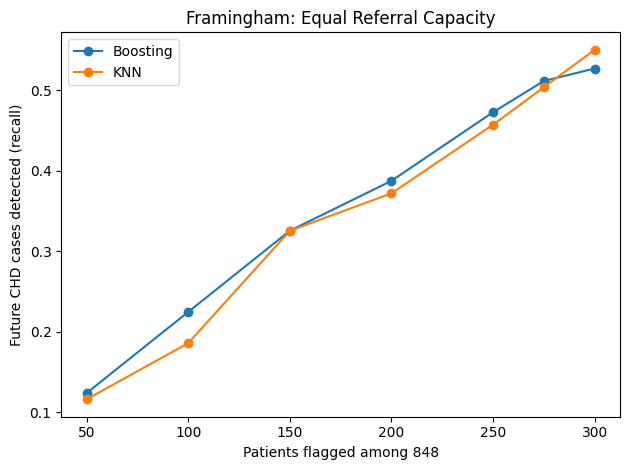

In [16]:

# Original thresholds selected using training data
CUTOFFS = {"Statlog": 0.42, "Framingham": 0.16}

rows = []

for name, obj in PRED.items():
    for model, cutoff in [
        ("KNN", CUTOFFS[name]),
        ("Boosting", CLASS_THRESHOLDS[name])
    ]:
        y, prob = obj["y"], obj[model]
        pred = prob >= cutoff

        tn, fp, fn, tp = confusion_matrix(
            y, pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "Dataset": name,
            "Model": model,
            "Cutoff": cutoff,
            "Detected": tp,
            "False alerts": fp,
            "Flagged": int(pred.sum()),
            "Precision": tp / max(tp + fp, 1),
            "Recall": tp / max(tp + fn, 1),
            "AP": average_precision_score(y, prob),
            "AUC": roc_auc_score(y, prob)
        })

threshold_comparison = pd.DataFrame(rows)
display(threshold_comparison.round(3))

# Fixed referral counts for Framingham
budgets = [50, 100, 150, 200, 250, 275, 300]
y = PRED["Framingham"]["y"]
capacity_rows = []

for model in ["KNN", "Boosting"]:
    prob = PRED["Framingham"][model]
    order = np.argsort(-prob, kind="stable")

    for n in budgets:
        top = order[:n]
        tp = int(y[top].sum())

        capacity_rows.append({
            "Model": model,
            "Flagged": n,
            "Detected": tp,
            "False alerts": n - tp,
            "Recall": tp / y.sum(),
            "Precision": tp / n
        })

capacity_results = pd.DataFrame(capacity_rows)
display(capacity_results.round(3))

for model, group in capacity_results.groupby("Model"):
    plt.plot(
        group["Flagged"], group["Recall"],
        marker="o", label=model
    )

plt.xlabel("Patients flagged among 848")
plt.ylabel("Future CHD cases detected (recall)")
plt.title("Framingham: Equal Referral Capacity")
plt.legend()
plt.tight_layout()
plt.savefig("week9_matched_referrals.png", dpi=300, bbox_inches="tight")
plt.show()

threshold_comparison.to_csv(
    "week9_knn_boost_thresholds.csv", index=False
)
capacity_results.to_csv(
    "week9_matched_referrals.csv", index=False
)


In [17]:

from numpy.random import default_rng

rng = default_rng(42)

y = PRED["Framingham"]["y"]
k = PRED["Framingham"]["KNN"]
b = PRED["Framingham"]["Boosting"]

kt = CUTOFFS["Framingham"]
bt = CLASS_THRESHOLDS["Framingham"]

boot_ap = []
boot_recall = []

for _ in range(2000):
    ix = rng.integers(0, len(y), len(y))

    if np.unique(y[ix]).size < 2:
        continue

    yy = y[ix]

    boot_ap.append(
        average_precision_score(yy, k[ix])
        - average_precision_score(yy, b[ix])
    )

    boot_recall.append(
        recall_score(yy, k[ix] >= kt)
        - recall_score(yy, b[ix] >= bt)
    )

comparisons = [
    (
        "AP difference (KNN minus Boosting)",
        boot_ap,
        average_precision_score(y, k)
        - average_precision_score(y, b)
    ),
    (
        "Recall difference at CV cutoffs",
        boot_recall,
        recall_score(y, k >= kt)
        - recall_score(y, b >= bt)
    )
]

for metric, samples, observed in comparisons:
    low, high = np.quantile(samples, [0.025, 0.975])

    print(
        f"{metric}: {observed:+.3f}, "
        f"95% paired bootstrap interval "
        f"[{low:+.3f}, {high:+.3f}]"
    )


AP difference (KNN minus Boosting): -0.014, 95% paired bootstrap interval [-0.046, +0.015]
Recall difference at CV cutoffs: +0.031, 95% paired bootstrap interval [-0.045, +0.106]


## 11. Discussion

The experiments indicate that increasing gradient boosting complexity did not consistently improve cardiovascular regression performance. Linear regression achieved lower held-out RMSE than tuned gradient boosting on both Statlog (22.211 versus 22.558) and Framingham (19.363 versus 19.499). On Statlog, increasing tree depth to four with 350 estimators reduced training RMSE to 4.495 but increased cross-validation RMSE to 25.148, indicating substantial overfitting. Limiting tree depth reduced this problem, improving cross-validation performance on both datasets. For disease classification, gradient boosting achieved test AUC values of 0.915 on Statlog and 0.678 on Framingham. Lowering the Framingham decision threshold improved positive-case detection but substantially increased false positives. Overall, additional model complexity offered limited benefits, while regularization and threshold selection had more consequential effects on generalization and classification decisions.

In [18]:
for name in REGRESSION:
    best_curve = learning_results[learning_results.Dataset == name].sort_values("CV RMSE").iloc[0]
    reference = regularization_results[
        (regularization_results.Dataset == name) &
        (regularization_results.Setting == "Reference")].iloc[0]
    best_reg = regularization_results[
        regularization_results.Dataset == name].sort_values("CV RMSE").iloc[0]
    tuned = heldout_results[
        (heldout_results.Dataset == name) &
        (heldout_results.Model == "Gradient boosting (tuned)")].iloc[0]
    linear = heldout_results[
        (heldout_results.Dataset == name) &
        (heldout_results.Model == "Linear regression")].iloc[0]
    print(f"{name} — learning-rate sweep: lowest CV RMSE {best_curve['CV RMSE']:.2f} "
          f"at rate {best_curve['Learning rate']:.2f} with {int(best_curve['Trees'])} trees.")
    print(f"  Regularization: reference CV RMSE {reference['CV RMSE']:.2f}; "
          f"lowest {best_reg['CV RMSE']:.2f} ({best_reg['Setting']}).")
    print(f"  Test RMSE: tuned boost {tuned['Test RMSE']:.2f}; "
          f"linear regression {linear['Test RMSE']:.2f}.")

for name in CLASSIFICATION:
    values = classification_results[classification_results.Dataset == name]
    default, selected = values.iloc[0], values.iloc[1]
    print(f"{name} classification — test AUC {default['Test AUC']:.3f}; "
          f"AP {default['Test AP']:.3f}. Recall {default['Test recall']:.3f} "
          f"(0.50 cutoff) vs {selected['Test recall']:.3f} "
          f"(CV cutoff); false positives {int(default['FP'])} vs {int(selected['FP'])}.")

Statlog — learning-rate sweep: lowest CV RMSE 21.90 at rate 0.03 with 50 trees.
  Regularization: reference CV RMSE 25.12; lowest 22.47 (Shallower trees).
  Test RMSE: tuned boost 22.56; linear regression 22.21.
Framingham — learning-rate sweep: lowest CV RMSE 19.41 at rate 0.10 with 50 trees.
  Regularization: reference CV RMSE 19.87; lowest 19.35 (Shallower trees).
  Test RMSE: tuned boost 19.50; linear regression 19.36.
Statlog classification — test AUC 0.915; AP 0.881. Recall 0.875 (0.50 cutoff) vs 0.792 (CV cutoff); false positives 5 vs 4.
Framingham classification — test AUC 0.678; AP 0.263. Recall 0.062 (0.50 cutoff) vs 0.473 (CV cutoff); false positives 18 vs 186.


## 12. Results and references

**Data:** UCI Statlog Heart Disease and Framingham cardiovascular datasets, preprocessed copies maintained in the capstone repository.

**Methods:** [Scikit-learn: GradientBoostingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html); [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html); [Ensembles](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting).

In [19]:
RESULT_TABLES = {
    "week9_eda.csv": eda,
    "week9_baselines_cv.csv": baseline_results,
    "week9_learning_rate_cv.csv": learning_results,
    "week9_depth_cv.csv": depth_results,
    "week9_regularization_cv.csv": regularization_results,
    "week9_tuning.csv": tuning_results,
    "week9_regression_test.csv": heldout_results,
    "week9_classification_tuning.csv": classification_tuning,
    "week9_classification_test.csv": classification_results
}
for filename, table in RESULT_TABLES.items():
    table.to_csv(filename, index=False)